# 04 - Team and role features

The interpretation step found the model's main failure mode: **"empty minutes"**.
Rookies who played a lot early on weak teams (Carter-Williams, Tyreke Evans,
O.J. Mayo, Jonny Flynn) were over-predicted: their minutes came from a thin
roster, not from quality.

Six candidate features (all known by the end of the 25-game window):

| Feature | Idea |
|---|---|
| `team_net_window` | debut team's net rating (margin per 100 possessions) during the window |
| `team_net_prev` | debut team's net rating over the previous season (rebuilding / tanking teams) |
| `mpg_x_team_net` | minutes weighted by team quality: heavy minutes on a good team vs on a bad one |
| `rel_pm36` | on-court +/- minus the team's margin in the same games (rough on/off) |
| `rotation_rank` | rank in team minutes during the window (competition for minutes) |
| `position` | BBRef position, 1 (PG) to 5 (C) |

**Rule:** the group is kept only if it beats the current model under the same
repeated cross-validation. Settings stay as tuned in 02 (plus a quick check of
the spline penalty, since more features can need a different one).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
from plot_style import apply_style, BLUE, ORANGE, AQUA, NEUTRAL, INK_2

apply_style()
dev = m.dev_set(md.add_pick_terms(m.load_table()))
WITH_TEAM = md.ALL + md.TEAM
print(f"Development set: {len(dev)} players | current features: {len(md.ALL)} | with team: {len(WITH_TEAM)}")
dev[md.TEAM].describe().round(2)

Development set: 683 players | current features: 22 | with team: 28


,team_net_prev,team_net_window,mpg_x_team_net,rel_pm36,rotation_rank,position
count,683.00,683.00,683.00,683.00,683.00,683.00
mean,-1.20,-1.01,-28.47,-0.77,9.81,3.03
std,4.63,5.31,85.64,1.02,3.64,1.42
min,-14.81,-16.91,-408.36,-4.95,1.00,1.00
25%,-4.59,-4.75,-59.27,-1.38,8.00,2.00
50%,-1.11,-1.09,-10.14,-0.81,10.00,3.00
75%,2.25,2.52,18.75,-0.16,13.00,4.00
max,10.95,15.18,304.74,3.23,17.00,5.00


**What to look for:** sensible ranges. Net ratings around 0 (league average) with
bad teams near -10 and good ones near +10; `rotation_rank` 1 = the player with the
most minutes on his team.

## 1. Quick check of the spline penalty with more features

In [2]:
rows = {}
for alpha in [100, 300, 1000]:
    t, _ = m.repeated_cv(lambda a=alpha: md.spline_ridge(alpha=a, features=WITH_TEAM), WITH_TEAM, dev)
    rows[alpha] = t["rmse"].mean()
alpha_check = pd.Series(rows, name="RMSE with team features")
SPLINE_ALPHA_TEAM = alpha_check.idxmin()
print(f"Best spline alpha with team features: {SPLINE_ALPHA_TEAM}")
alpha_check.round(3)

Best spline alpha with team features: 1000


100     1.979
300     1.916
1000    1.897
Name: RMSE with team features, dtype: float64

## 2. Does the team group help? (same 25 paired splits)

In [3]:
from sklearn.ensemble import VotingRegressor

def ensemble_team():
    return VotingRegressor([
        ("linear", md.spline_ridge(alpha=SPLINE_ALPHA_TEAM, features=WITH_TEAM)),
        ("boosting", md.boosting()),
    ])

CANDIDATES = {
    "Baseline (pick only)": (md.baseline, ["pick"]),
    "Ensemble - current": (md.ensemble, md.ALL),
    "Ensemble + team": (ensemble_team, WITH_TEAM),
    "Ridge - current": (md.ridge, md.ALL),
    "Ridge + team": (md.ridge, WITH_TEAM),
}
tables, oofs = {}, {}
for name, (make, feats) in CANDIDATES.items():
    tables[name], oofs[name] = m.repeated_cv(make, feats, dev)

def wins(a, b):
    return int((tables[a]["rmse"].values < tables[b]["rmse"].values).sum())

summary = pd.DataFrame({
    name: {"RMSE": t["rmse"].mean(), "MAE": t["mae"].mean(), "Spearman": t["spearman"].mean()}
    for name, t in tables.items()}).T
summary["beats its 'current' version (of 25)"] = [
    None, None, wins("Ensemble + team", "Ensemble - current"), None,
    wins("Ridge + team", "Ridge - current")]
summary.round(3)

,RMSE,MAE,Spearman,beats its 'current' version (of 25)
Baseline (pick only),2.102,1.377,0.274,NaN
Ensemble - current,1.889,1.230,0.438,NaN
Ensemble + team,1.899,1.231,0.431,10.0
Ridge - current,1.904,1.248,0.467,NaN
Ridge + team,1.903,1.248,0.469,14.0


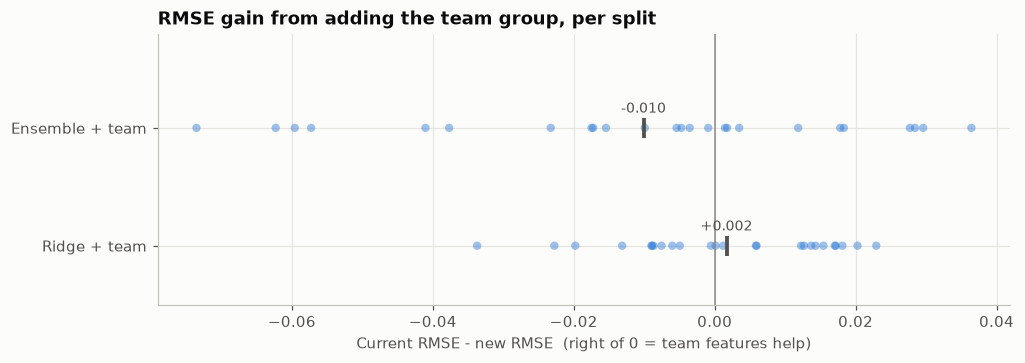

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
pairs = [("Ensemble + team", "Ensemble - current"), ("Ridge + team", "Ridge - current")]
for i, (new, old) in enumerate(pairs):
    gain = tables[old]["rmse"].values - tables[new]["rmse"].values
    ax.scatter(gain, [i] * len(gain), s=30, color=BLUE, alpha=0.45, edgecolor="none")
    ax.scatter(gain.mean(), i, s=160, marker="|", color=INK_2, linewidths=2.5)
    ax.annotate(f"{gain.mean():+.3f}", (gain.mean(), i), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_yticks(range(len(pairs)), [p[0] for p in pairs])
ax.set_ylim(len(pairs) - 0.5, -0.8)
ax.set(title="RMSE gain from adding the team group, per split",
       xlabel="Current RMSE - new RMSE  (right of 0 = team features help)")
plt.show()

**What to look for:** same reading as in 02. Most dots right of 0 = a real gain;
dots on both sides around 0 = the team group adds nothing reliable.

## 3. Which team features carry the gain? (add one at a time)
Each feature is added alone to the current ensemble. Negative = it helps.

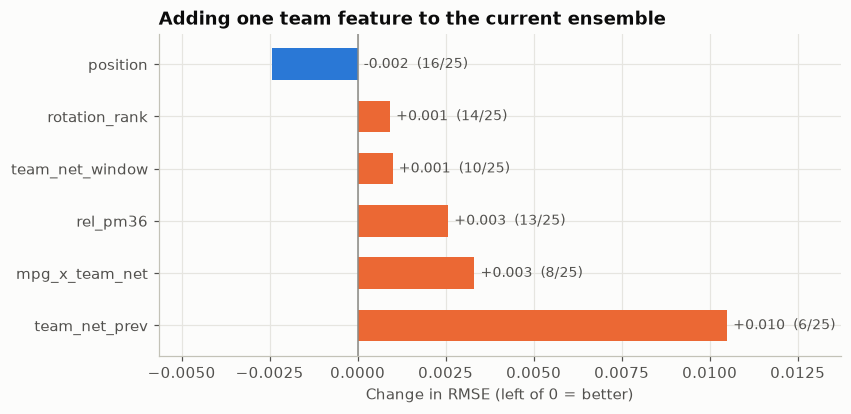

,RMSE change,splits improved (of 25)
position,-0.0024,16.0
rotation_rank,0.0009,14.0
team_net_window,0.0010,10.0
rel_pm36,0.0026,13.0
mpg_x_team_net,0.0033,8.0
team_net_prev,0.0105,6.0


In [5]:
base_rmse = tables["Ensemble - current"]["rmse"].values
single = {}
for f in md.TEAM:
    feats = md.ALL + [f]
    t, _ = m.repeated_cv(lambda feats=feats: md.ensemble(features=feats), feats, dev)
    single[f] = {"RMSE change": (t["rmse"].values - base_rmse).mean(),
                 "splits improved (of 25)": int((t["rmse"].values < base_rmse).sum())}
single = pd.DataFrame(single).T.sort_values("RMSE change")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(single.index, single["RMSE change"], height=0.6,
        color=[BLUE if v < 0 else ORANGE for v in single["RMSE change"]])
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.invert_yaxis()
ax.margins(x=0.25)
for y, (v, w) in enumerate(zip(single["RMSE change"], single["splits improved (of 25)"])):
    # labels always start right of the bar end or of 0, whichever is further right
    ax.annotate(f"{v:+.3f}  ({int(w)}/25)", (max(v, 0), y), xytext=(4, 0),
                textcoords="offset points", va="center", ha="left",
                fontsize=9, color=INK_2)
ax.set(title="Adding one team feature to the current ensemble",
       xlabel="Change in RMSE (left of 0 = better)")
plt.show()
single.round(4)

## 4. Did it fix the "empty minutes" problem?

First the general check: average error by the quality of the rookie's team
(5 equal groups by window net rating). If the current model over-predicts rookies
on bad teams, its bar for the worst teams will be clearly negative.

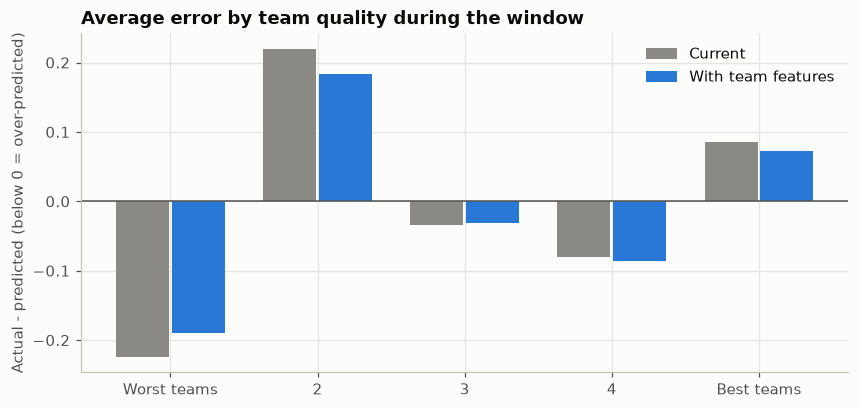

,Current,With team features
team_net_window,,
Worst teams,-0.224,-0.190
2,0.220,0.184
3,-0.034,-0.032
4,-0.080,-0.086
Best teams,0.085,0.073


In [6]:
cur, new = oofs["Ensemble - current"], oofs["Ensemble + team"]
q = pd.qcut(dev["team_net_window"], 5, labels=["Worst teams", "2", "3", "4", "Best teams"])
err = pd.DataFrame({
    "Current": (dev[m.TARGET] - cur).groupby(q, observed=True).mean(),
    "With team features": (dev[m.TARGET] - new).groupby(q, observed=True).mean(),
})

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(err))
ax.bar(x - 0.19, err["Current"], width=0.36, color=NEUTRAL, label="Current")
ax.bar(x + 0.19, err["With team features"], width=0.36, color=BLUE, label="With team features")
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_xticks(x, err.index)
ax.set(title="Average error by team quality during the window",
       ylabel="Actual - predicted (below 0 = over-predicted)")
ax.legend()
plt.show()
err.round(3)

In [7]:
EMPTY = ["Michael Carter-Williams", "Tyreke Evans", "O.J. Mayo", "Jonny Flynn",
         "Landry Fields", "Yao Ming", "LaMarcus Aldridge", "Ben Gordon"]
cols = ["player_name", "pick", "mpg", "team_net_window", "rotation_rank", "rel_pm36", m.TARGET]
view = dev.assign(current=cur, with_team=new)
view = view[view["player_name"].isin(EMPTY)][cols + ["current", "with_team"]]
view["closer now?"] = (view[m.TARGET] - view["with_team"]).abs() < (view[m.TARGET] - view["current"]).abs()
view.round(2)

,player_name,pick,mpg,team_net_window,rotation_rank,rel_pm36,target_vorp,current,with_team,closer now?
99,Yao Ming,1,25.44,3.68,3.0,-1.87,6.0,2.42,2.76,True
192,Ben Gordon,3,23.16,-3.87,6.0,-1.01,4.7,0.92,1.62,True
292,LaMarcus Aldridge,2,16.96,-5.15,8.0,-0.22,4.8,0.96,0.86,False
392,O.J. Mayo,3,37.60,-4.18,1.0,-0.75,2.0,6.07,6.00,True
442,Tyreke Evans,4,36.00,-1.02,1.0,-1.31,2.7,7.63,7.20,True
444,Jonny Flynn,6,29.24,-11.06,3.0,-1.31,-0.3,4.56,4.46,True
524,Landry Fields,39,31.36,1.96,5.0,0.97,0.2,4.07,3.91,True
650,Michael Carter-Williams,11,36.80,-8.21,6.0,-0.18,0.2,6.62,5.61,True


**What to look for:** whether the bad-team bar moves toward 0, and whether the
named "empty minutes" cases move toward what really happened. The last four names
were the opposite case (good players the model pulled down).